Total questions: 40
Total categories: 8
TAXONOMY
Diabetes Information
  - Diabetes Basics
  - Symptoms
Daily Care
  - Blood Sugar Monitoring
  - Healthy Food
Treatment
  - Exercise
  - Medicines
Blood Sugar Problems
  - Low Blood Sugar
  - High Blood Sugar
DOMAIN CONCEPTS
- Diabetes
- Blood Sugar
- Insulin
- Glucose Meter
- Healthy Food
- Exercise
- Medicine
- Hypoglycemia
- Hyperglycemia
- Doctor
DOMAIN RELATIONSHIPS
- Diabetes affects blood sugar.
- Insulin helps control blood sugar.
- A glucose meter measures blood sugar.
- Healthy food supports diabetes care.
- Exercise can affect blood sugar.
- Medicine may be prescribed to manage diabetes.
- Hypoglycemia means low blood sugar.
- Hyperglycemia means high blood sugar.
- A doctor advises about medicines.
- A doctor helps manage diabetes.
PREPROCESSING EXAMPLE
Before: What is diabetes?
After: diabetes
MODEL EVALUATION
Accuracy: 0.6
Precision: 0.53
Recall: 0.6
F1 Score: 0.55


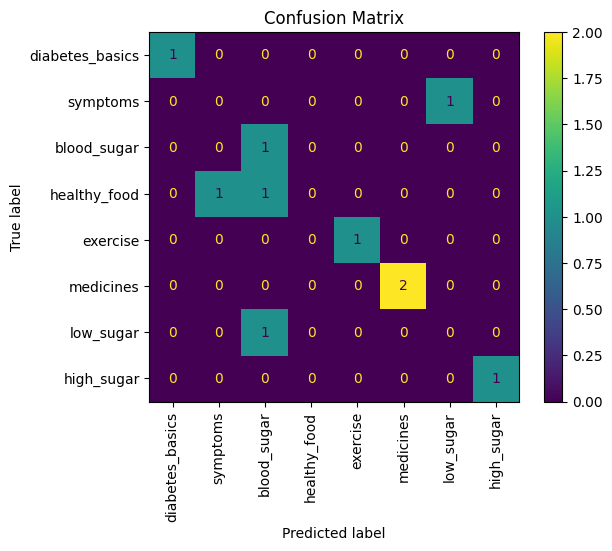

TESTING
Question: What is diabetes?
Answer: Diabetes is a condition in which blood sugar becomes too high. It happens when the body does not make enough insulin or cannot use insulin properly.
Question: I feel thirsty again and again
Answer: Sorry, I can answer only questions related to diabetes care.
Question: How can I treat a broken bone?
Answer: Sorry, I can answer only questions related to diabetes care.
Question: blue sky running quickly
Answer: Sorry, I can answer only questions related to diabetes care.
Question: A diabetic person is unconscious
Answer: EMERGENCY: Call your local emergency number immediately. Do not give food, drink or medicine by mouth to an unconscious person. Follow emergency operator instructions.
DIABETES CARE INFORMATION ASSISTANT
Type 'exit' to stop.


In [ ]:
# UCS420 - Assignment 10
# Diabetes Care Information Assistant
# Roll Number: 102416120

# Install and download required NLTK data
!pip -q install nltk scikit-learn matplotlib ipywidgets

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. DATASET: 40 questions in 8 categories
# --------------------------------------------------

data = {
    "diabetes_basics": [
        "What is diabetes?",
        "Explain diabetes in simple words",
        "What happens in the body during diabetes?",
        "What is type one diabetes?",
        "What is type two diabetes?"
    ],

    "symptoms": [
        "What are the symptoms of diabetes?",
        "Why do I feel thirsty all the time?",
        "Can diabetes cause tiredness?",
        "Why does a person urinate frequently?",
        "Can diabetes cause blurry vision?"
    ],

    "blood_sugar": [
        "How can I check my blood sugar?",
        "What is a glucose meter?",
        "When should I check blood glucose?",
        "How can I record my sugar readings?",
        "What does a blood sugar reading mean?"
    ],

    "healthy_food": [
        "What food is good for diabetes?",
        "What should a diabetic person eat?",
        "Are vegetables good for blood sugar?",
        "Why is a balanced diet important?",
        "Can I eat fruits if I have diabetes?"
    ],

    "exercise": [
        "What exercise is good for diabetes?",
        "Can walking help control blood sugar?",
        "How often should I exercise?",
        "Is physical activity helpful for diabetes?",
        "What are simple exercises for diabetic people?"
    ],

    "medicines": [
        "Why are diabetes medicines given?",
        "What is insulin?",
        "Should I stop my diabetes medicine?",
        "What should I ask about my medicine?",
        "Can I change my medicine dose myself?"
    ],

    "low_sugar": [
        "What are the signs of low blood sugar?",
        "What is hypoglycemia?",
        "Why do I feel shaky and sweaty?",
        "What happens when blood sugar becomes too low?",
        "How can I identify low glucose?"
    ],

    "high_sugar": [
        "What are the signs of high blood sugar?",
        "What is hyperglycemia?",
        "Why is my blood sugar high?",
        "Can high sugar cause frequent urination?",
        "What should I do about repeated high readings?"
    ]
}

questions = []
labels = []

for category in data:
    for question in data[category]:
        questions.append(question)
        labels.append(category)

print("Total questions:", len(questions))
print("Total categories:", len(data))

# --------------------------------------------------
# 2. HIERARCHICAL TAXONOMY
# --------------------------------------------------

taxonomy = {
    "Diabetes Information": ["Diabetes Basics", "Symptoms"],
    "Daily Care": ["Blood Sugar Monitoring", "Healthy Food"],
    "Treatment": ["Exercise", "Medicines"],
    "Blood Sugar Problems": ["Low Blood Sugar", "High Blood Sugar"]
}

print("TAXONOMY")
for main_category, sub_categories in taxonomy.items():
    print(main_category)
    for sub_category in sub_categories:
        print("  -", sub_category)

# --------------------------------------------------
# 3. DOMAIN CONCEPTS AND RELATIONSHIPS
# --------------------------------------------------

concepts = [
    "Diabetes", "Blood Sugar", "Insulin", "Glucose Meter",
    "Healthy Food", "Exercise", "Medicine", "Hypoglycemia",
    "Hyperglycemia", "Doctor"
]

relationships = [
    "Diabetes affects blood sugar.",
    "Insulin helps control blood sugar.",
    "A glucose meter measures blood sugar.",
    "Healthy food supports diabetes care.",
    "Exercise can affect blood sugar.",
    "Medicine may be prescribed to manage diabetes.",
    "Hypoglycemia means low blood sugar.",
    "Hyperglycemia means high blood sugar.",
    "A doctor advises about medicines.",
    "A doctor helps manage diabetes."
]

print("DOMAIN CONCEPTS")
for concept in concepts:
    print("-", concept)

print("DOMAIN RELATIONSHIPS")
for relation in relationships:
    print("-", relation)

# --------------------------------------------------
# 4. TEXT PREPROCESSING
# Lowercase, tokenization, stopword removal, lemmatization
# --------------------------------------------------

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    words = nltk.word_tokenize(text)

    new_words = []
    for word in words:
        if word.isalpha() and word not in stop_words:
            new_words.append(lemmatizer.lemmatize(word))

    return " ".join(new_words)

print("PREPROCESSING EXAMPLE")
print("Before:", questions[0])
print("After:", preprocess(questions[0]))

# --------------------------------------------------
# 5. TF-IDF AND NAIVE BAYES CLASSIFIER
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    questions, labels, test_size=0.25, random_state=42, stratify=labels
)

vectorizer = TfidfVectorizer(preprocessor=preprocess)
X_train_vector = vectorizer.fit_transform(X_train)
X_test_vector = vectorizer.transform(X_test)

model = MultinomialNB()
model.fit(X_train_vector, y_train)

predictions = model.predict(X_test_vector)

# --------------------------------------------------
# 6. MODEL EVALUATION
# --------------------------------------------------

print("MODEL EVALUATION")
print("Accuracy:", round(accuracy_score(y_test, predictions), 2))
print("Precision:", round(precision_score(y_test, predictions, average="weighted", zero_division=0), 2))
print("Recall:", round(recall_score(y_test, predictions, average="weighted", zero_division=0), 2))
print("F1 Score:", round(f1_score(y_test, predictions, average="weighted", zero_division=0), 2))

matrix = confusion_matrix(y_test, predictions, labels=list(data.keys()))
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=list(data.keys()))
display.plot(xticks_rotation=90)
plt.title("Confusion Matrix")
plt.show()

# --------------------------------------------------
# 7. KNOWLEDGE BASE
# --------------------------------------------------

knowledge = {
    "diabetes_basics": "Diabetes is a condition in which blood sugar becomes too high. It happens when the body does not make enough insulin or cannot use insulin properly.",
    "symptoms": "Common symptoms may include increased thirst, frequent urination, tiredness and blurred vision. A doctor can confirm diabetes through proper tests.",
    "blood_sugar": "A glucose meter is used to check blood sugar. Follow the testing schedule given by your doctor and record your readings.",
    "healthy_food": "Choose balanced meals with vegetables, fruits in suitable portions, whole grains and healthy protein. A dietitian can help prepare a personal food plan.",
    "exercise": "Walking and other regular physical activities can support general health and blood sugar management. Choose activities suitable for your health.",
    "medicines": "Take diabetes medicines only as prescribed. Do not stop or change medicine or insulin doses without asking your doctor.",
    "low_sugar": "Low blood sugar may cause sweating, shaking, hunger, dizziness or confusion. If the person is awake and can swallow, follow their medical care plan. If unconscious or having a seizure, call emergency services and do not give anything by mouth.",
    "high_sugar": "High blood sugar may cause thirst, frequent urination and tiredness. Follow your care plan and contact your doctor for repeated high readings. Severe confusion, vomiting or difficult breathing needs urgent medical help."
}

# --------------------------------------------------
# 8. REASONING RULES AND ASSISTANT
# --------------------------------------------------

def get_answer(user_question):
    question = user_question.lower()

    # Rule 1: Emergency handling
    emergency_words = ["unconscious", "seizure", "cannot wake", "can't wake",
                       "not breathing", "difficulty breathing"]
    for word in emergency_words:
        if word in question:
            return "EMERGENCY: Call your local emergency number immediately. Do not give food, drink or medicine by mouth to an unconscious person. Follow emergency operator instructions."

    # Rule 2: Unsupported questions
    diabetes_words = ["diabetes", "sugar", "glucose", "insulin", "diabetic",
                      "hypoglycemia", "hyperglycemia"]
    if not any(word in question for word in diabetes_words):
        return "Sorry, I can answer only questions related to diabetes care."

    # Rule 3: Predict the question category
    question_vector = vectorizer.transform([user_question])
    probabilities = model.predict_proba(question_vector)[0]
    best_index = probabilities.argmax()
    confidence = probabilities[best_index]
    category = model.classes_[best_index]

    # Rule 4: Low confidence handling
    if confidence < 0.15:
        return "I am not sure about your question. Please write it in a simpler way or ask your doctor."

    # Rule 5: Medicine safety
    if "stop" in question or "change" in question or "dose" in question:
        if "medicine" in question or "insulin" in question or "diabetes" in question:
            return "Do not stop or change your medicine dose yourself. Please consult your doctor."

    # Rule 6: Retrieve answer from knowledge base
    return knowledge[category]

# --------------------------------------------------
# 9. TESTING THE ASSISTANT
# --------------------------------------------------

test_questions = [
    "What is diabetes?",                         # Defined intent
    "I feel thirsty again and again",            # Reworded question
    "How can I treat a broken bone?",            # Unsupported question
    "blue sky running quickly",                  # Low confidence / unclear
    "A diabetic person is unconscious"           # Emergency question
]

print("TESTING")
for question in test_questions:
    print("Question:", question)
    print("Answer:", get_answer(question))

# --------------------------------------------------
# 10. SIMPLE INTERACTIVE ASSISTANT
# --------------------------------------------------

print("DIABETES CARE INFORMATION ASSISTANT")
print("Type 'exit' to stop.")

while True:
    user_question = input("Enter your question: ")

    if user_question.lower() == "exit":
        print("Thank you for using the assistant.")
        break

    print("Assistant:", get_answer(user_question))

# Note: This is a student project for educational purposes.
# It does not diagnose diseases or replace a doctor.
